# Real-time Singapore Taxi Availability + Weather — 2-hour Forecast Demo

Live **data.gov.sg** taxi GPS points are spatially joined to the **URA Master Plan 2019 subzone polygons**
to count available taxis per planning area, merged with the live 2-hour weather forecast in **DuckDB**,
and fed to a 2-hour-ahead taxi-count model with hour-aware **anomaly alerts**. This notebook is the
single-machine walkthrough of a containerised pipeline (Airflow → Kafka/Flink → DuckDB → MLflow → FastAPI →
dashboard) whose code is in `pipeline/` of this folder.

**▶ Demo: Runtime → Run all — the Gradio link appears at the bottom in about 2–4 minutes.**
Runtime: **CPU** is enough (no GPU needed). The RandomForest trains in seconds, so there is no pre-trained model to download.

*Individual project · SIT Graduate Certificate in AI Practice — AI Foundations & Engineering Practice, Week 2.*

**Live endpoints**
- Taxi availability — `https://api.data.gov.sg/v1/transport/taxi-availability` (v1, keyless)
- 2-hour weather — `https://api-open.data.gov.sg/v2/real-time/api/two-hr-forecast` (v2; an API key is optional and only raises the rate limit)

> **Optional API key:** add a Colab secret named `DATA_GOV_API_KEY` (🔑 icon in the left sidebar) with your own data.gov.sg key.
> Without it the APIs are called keyless; if any live call fails (offline, rate-limited) the notebook falls back to the
> bundled cached samples in `data/` and says so in its output.

**Stages:** 1 Live ingest · 2 GeoJSON spatial join + map · 3 Merge + DuckDB · 4 Train the 2-hour model ·
5 Predict +2 h · 6 Anomaly alerts · 7 Map to the production stack · 8 Interactive Gradio app.


In [ ]:
# ── Setup: install missing packages and fetch the support files from GitHub ─────────
# Run from the project folder (locally) or from /content (Colab). Files that already exist are not re-downloaded.
import importlib.util, os, subprocess, sys, urllib.request

missing = [p for p in ("geopandas", "duckdb", "gradio") if importlib.util.find_spec(p) is None]
if missing:
    print("Installing:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

RAW = "https://raw.githubusercontent.com/tantg88888/sit-ai-practice-2026/main/week2-realtime-taxi-forecasting/"
SUPPORT_FILES = [
    "lib/__init__.py",
    "lib/live_clients.py",
    "lib/geo.py",
    "data/sample_taxi_availability.json",
    "data/sample_2h_weather_forecast.json",
    "data/taxi_weather_2h_prediction_dataset.csv",
    "shared_assets/MasterPlan2019SubzoneBoundaryNoSeaGEOJSON.geojson",
]
PROJECT_ROOT = os.getcwd()
for rel in SUPPORT_FILES:
    dst = os.path.join(PROJECT_ROOT, *rel.split("/"))
    if os.path.exists(dst) and os.path.getsize(dst) > 0:
        continue
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    try:
        urllib.request.urlretrieve(RAW + rel, dst)
        print(f"downloaded {rel} ({os.path.getsize(dst)/1e6:.2f} MB)")
    except Exception as exc:
        if rel == "lib/__init__.py":
            open(dst, "w").close()          # an empty package marker is enough
        else:
            raise RuntimeError(f"Could not download {RAW + rel}: {exc}") from exc
print("Support files ready in", PROJECT_ROOT)


In [ ]:
# ── Optional data.gov.sg API key (Colab secret DATA_GOV_API_KEY → env var) ──────────
# The key is never printed or saved. Without it, the APIs are called keyless and any failed call
# falls back to the cached samples in data/.
import os
try:
    from google.colab import userdata
    _key = userdata.get("DATA_GOV_API_KEY")
    if _key:
        os.environ["DATA_GOV_API_KEY"] = _key.strip()
        print("DATA_GOV_API_KEY loaded from Colab secrets.")
except Exception as exc:
    print(f"No Colab secret DATA_GOV_API_KEY ({type(exc).__name__}) - continuing without a key.")


In [ ]:
import os, sys
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
PROJECT_ROOT = os.getcwd()                      # folder that holds lib/, data/, shared_assets/
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
from lib import live_clients as lc, geo
DATA = os.path.join(PROJECT_ROOT, "data")
pd.set_option("display.width", 140)
print("data.gov.sg API key:", lc.key_status())


## Stage 1 — Live ingestion (taxi v1 + weather v2)

Mirrors the Airflow `fetch_*` tasks and the Kafka producer: one taxi snapshot and the 2-hour
weather forecast. If `DATA_GOV_API_KEY` is set it is sent in the `X-API-Key` header. Each line below says
whether the data is **LIVE** or a **CACHED sample** (fallback when a live call fails).


In [ ]:
taxi = lc.fetch_taxi()
weather = lc.fetch_weather()
print(f"TAXI    [{taxi['source']}]  available taxis = {taxi['available_taxis']:,}  @ {taxi['api_timestamp']}")
print(f"WEATHER [{weather['source']}]  areas = {weather['n_areas']}  rainy = {weather['n_rain_areas']}  @ {weather['update_timestamp']}")
display(taxi["points"].head(3))
display(weather["forecasts"][["area","forecast","is_rain"]].head(5))
if "CACHED" in taxi["source"] or "CACHED" in weather["source"]:
    print("NOTE: at least one live call failed - the CACHED sample above is used for the rest of the notebook.")

TAXI    [LIVE data.gov.sg]  available taxis = 1,852  @ 2026-06-27T15:56:03+08:00
WEATHER [LIVE data.gov.sg]  areas = 47  rainy = 0  @ 2026-06-27T15:36:30+08:00


,longitude,latitude
0,103.63610,1.33358
1,103.63737,1.33231
2,103.66178,1.30649


,area,forecast,is_rain
0,Ang Mo Kio,Partly Cloudy (Day),0
1,Bedok,Partly Cloudy (Day),0
2,Bishan,Partly Cloudy (Day),0
3,Boon Lay,Partly Cloudy (Day),0
4,Bukit Batok,Partly Cloudy (Day),0


## Stage 2 — GeoJSON spatial join: taxis → planning area

Load the 332 subzone polygons (normalised to WGS84), build a GeoDataFrame of taxi points, and
`geopandas.sjoin(predicate="intersects")` each point into its polygon, then count by `PLN_AREA_N`.
This is the same join the Airflow `join_taxi_to_planning_area` task performs.

In [ ]:
subzones = geo.load_subzones()
print(f"Subzone polygons: {len(subzones)} | planning areas: {subzones['PLN_AREA_N'].nunique()}")
joined, taxi_by_area = geo.join_taxis_to_areas(taxi["points"], subzones)
print(f"Matched {len(joined):,}/{len(taxi['points']):,} taxi points into {len(taxi_by_area)} planning areas")
display(taxi_by_area.head(8))

Subzone polygons: 332 | planning areas: 55
Matched 1,851/1,852 taxi points into 51 planning areas


,planning_area,available_taxi_count
0,CHANGI,147
1,ANG MO KIO,119
2,BUKIT MERAH,103
3,GEYLANG,97
4,YISHUN,93
5,HOUGANG,90
6,BEDOK,86
7,KALLANG,79


### The join, visualised — a live choropleth of taxi availability by planning area

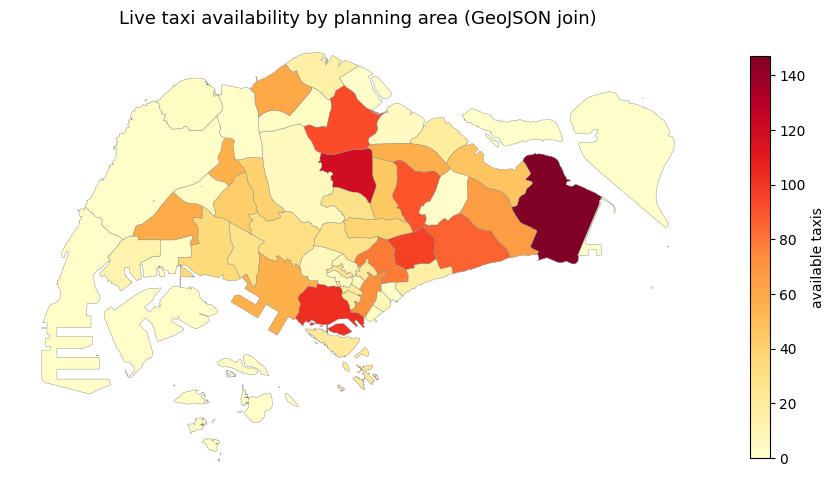

In [ ]:
ax = geo.choropleth(taxi_by_area, subzones,
                    title="Live taxi availability by planning area (GeoJSON join)")
plt.show()

## Stage 3 — Merge taxi-by-area with weather-by-area, store in DuckDB

Join the area-level taxi counts to the live weather forecast on the planning-area name (both
upper-cased), then load to DuckDB and query — the same shape as the pipeline's merged taxi + weather table.

In [ ]:
import duckdb
area_taxi = taxi_by_area.copy(); area_taxi["area_key"] = area_taxi["planning_area"].str.upper()
merged = weather["forecasts"].merge(area_taxi, on="area_key", how="left")
merged["available_taxi_count"] = merged["available_taxi_count"].fillna(0).astype(int)
merged = merged[["area","forecast","is_rain","available_taxi_count"]]

con = duckdb.connect(os.path.join(DATA, "demo_live.duckdb"))
con.register("m_df", merged)
con.execute("CREATE OR REPLACE TABLE weather_taxi_now AS SELECT * FROM m_df")
top = con.execute('''
    SELECT area, forecast, is_rain, available_taxi_count
    FROM weather_taxi_now ORDER BY available_taxi_count DESC LIMIT 8
''').df()
print(f"Total available taxis now: {taxi['available_taxis']:,}  across {merged['available_taxi_count'].gt(0).sum()} areas")
display(top)

Total available taxis now: 1,852  across 41 areas


,area,forecast,is_rain,available_taxi_count
0,Changi,Partly Cloudy (Day),0,147
1,Ang Mo Kio,Partly Cloudy (Day),0,119
2,Bukit Merah,Partly Cloudy (Day),0,103
3,Geylang,Partly Cloudy (Day),0,97
4,Yishun,Partly Cloudy (Day),0,93
5,Hougang,Partly Cloudy (Day),0,90
6,Bedok,Partly Cloudy (Day),0,86
7,Kallang,Partly Cloudy (Day),0,79


## Stage 4 — Train the 2-hour prediction model

A single live snapshot has no "2 hours later" label, so the model trains on the project's prepared dataset
(`data/taxi_weather_2h_prediction_dataset.csv`: area-level taxi counts collected by the pipeline, each paired
with the count in the same area ~2 hours later and the 2-hour weather forecast). The live area counts above are
exactly the `current_taxi_count` feature this model consumes. In the full stack, `train_*_mlflow.py` logs and
registers the model in MLflow as `taxi_availability_2h_model@champion`.

> **Honest caveat:** this cell uses a **random 80/20 split**. For time-series data that is optimistic — rows a few
> minutes apart from the same area land on both sides of the split. The next cell re-scores the same model on a
> **chronological** hold-out (train on the earliest 80 % of timestamps, test on the latest 20 %), which is the
> fairer number. The recorded run of this cell printed MAE 13.37, RMSE 23.53, R² 0.908.


MAE = 13.37 taxis | RMSE = 23.53 | R2 = 0.908


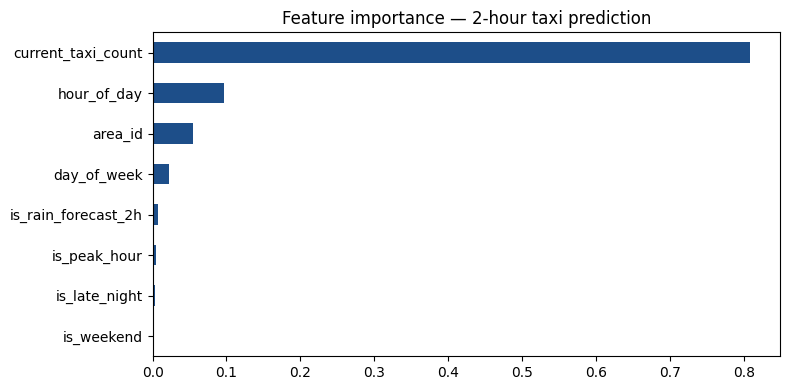

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv(os.path.join(DATA, "taxi_weather_2h_prediction_dataset.csv"))
df["area_id"] = df["planning_area"].astype("category").cat.codes
FEATURES = ["current_taxi_count","hour_of_day","day_of_week","is_weekend",
            "is_peak_hour","is_late_night","is_rain_forecast_2h","area_id"]
TARGET = "target_taxi_count_2h"
d = df.dropna(subset=FEATURES+[TARGET])
Xtr,Xte,ytr,yte = train_test_split(d[FEATURES], d[TARGET], test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=200, max_depth=14, random_state=42, n_jobs=-1).fit(Xtr,ytr)
pred = model.predict(Xte)
print(f"MAE = {mean_absolute_error(yte,pred):.2f} taxis | RMSE = {np.sqrt(mean_squared_error(yte,pred)):.2f} | R2 = {r2_score(yte,pred):.3f}")
pd.Series(model.feature_importances_, index=FEATURES).sort_values().plot.barh(
    figsize=(8,4), color="#1D4E89", title="Feature importance — 2-hour taxi prediction"); plt.tight_layout(); plt.show()

### Fairer check — chronological hold-out and a naive baseline

Same model and features, but trained only on earlier timestamps and scored on the latest 20 %. The naive baseline predicts "same number of taxis as now"; a useful model should beat it.


In [ ]:
# Fairer check: chronological hold-out (no future rows in training).
ts = pd.to_datetime(d["timestamp"], utc=True).dt.tz_convert("Asia/Singapore")
cut = ts.sort_values().iloc[int(len(ts) * 0.8)]
tr, te = d[ts < cut], d[ts >= cut]
m_time = RandomForestRegressor(n_estimators=200, max_depth=14, random_state=42, n_jobs=-1).fit(tr[FEATURES], tr[TARGET])
p_time = m_time.predict(te[FEATURES])
print(f"Dataset: {len(d):,} rows, {d['planning_area'].nunique()} planning areas, "
      f"{ts.min():%Y-%m-%d %H:%M} to {ts.max():%Y-%m-%d %H:%M} SGT")
print(f"Chronological hold-out ({len(te):,} latest rows, from {cut:%Y-%m-%d %H:%M}): "
      f"MAE = {mean_absolute_error(te[TARGET], p_time):.2f} taxis | "
      f"RMSE = {np.sqrt(mean_squared_error(te[TARGET], p_time)):.2f} | R2 = {r2_score(te[TARGET], p_time):.3f}")
naive = te["current_taxi_count"]
print(f"Naive baseline on the same rows (taxis in 2 h = taxis now): "
      f"MAE = {mean_absolute_error(te[TARGET], naive):.2f} taxis | R2 = {r2_score(te[TARGET], naive):.3f}")


## Stage 5 — Predict the next 2 hours per planning area

,planning_area,current_taxi_count,pred_2h,is_rain_forecast_2h
20754,CHANGI,775,721,0
20757,DOWNTOWN CORE,308,259,0
20788,TAMPINES,182,180,0
20795,YISHUN,166,143,0
20758,GEYLANG,153,102,0
20745,ANG MO KIO,143,110,0
20759,HOUGANG,141,105,0
20746,BEDOK,138,121,0


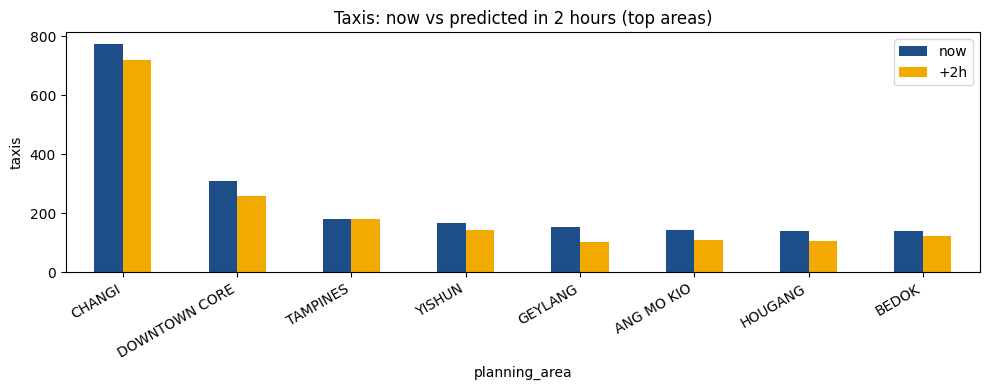

In [ ]:
latest = d.sort_values("timestamp").groupby("planning_area").tail(1).copy()
latest["pred_2h"] = model.predict(latest[FEATURES]).round().astype(int)
view = latest.sort_values("current_taxi_count", ascending=False).head(8)[["planning_area","current_taxi_count","pred_2h","is_rain_forecast_2h"]]
display(view)
ax = view.set_index("planning_area")[["current_taxi_count","pred_2h"]].plot.bar(figsize=(10,4), color=["#1D4E89","#F2A900"])
ax.set_title("Taxis: now vs predicted in 2 hours (top areas)"); ax.set_ylabel("taxis")
plt.xticks(rotation=30, ha="right"); plt.legend(["now","+2h"]); plt.tight_layout(); plt.show()

## Stage 6 — Anomaly detection & alerts

Compare an area's latest count to its **typical count at the same hour**; |z| ≥ 2.5 fires an alert
on the dashboard. We show a normal reading vs an injected drop.

In [ ]:
def detect(area, hist, value, z=2.5):
    cur_hour = latest[latest['planning_area']==area]['hour_of_day'].iloc[0]
    ctx = hist[(hist.planning_area==area)&(hist.hour_of_day==cur_hour)]['current_taxi_count']
    if len(ctx)<5: return None
    mu,sd = ctx.mean(), ctx.std()
    zz = (value-mu)/sd if sd>0 else 0
    return dict(area=area, value=value, typical=round(mu,1), z=round(zz,2), alert=abs(zz)>=z,
                direction="LOW" if zz<0 else "HIGH")
busy = latest.sort_values('current_taxi_count', ascending=False)['planning_area'].iloc[0]
base = int(latest[latest.planning_area==busy]['current_taxi_count'].iloc[0])
print("normal :", detect(busy, d, base))
print("drop   :", detect(busy, d, max(0, base//4)))

normal : {'area': 'CHANGI', 'value': 775, 'typical': 634.5, 'z': 1.12, 'alert': False, 'direction': 'HIGH'}
drop   : {'area': 'CHANGI', 'value': 193, 'typical': 634.5, 'z': -3.51, 'alert': True, 'direction': 'LOW'}


## Stage 7 — How this maps to the production stack (`pipeline/`)

| Notebook stage | Production component |
|---|---|
| Stage 1 live ingest | **Airflow** `fetch_taxi_api` / `fetch_current_rainfall_api` tasks (`01_airflow_batch`) · **Kafka producer** polling every 15 s (`02_kafka_streaming`) |
| Stage 2 GeoJSON join | **Airflow** `join_taxi_to_planning_area` (point-in-polygon in `jobs/geo_utils.py`) · Kafka dashboard (geopandas) |
| Stage 3 merge + DuckDB | Airflow load tasks (single-writer pool) · **Kafka consumer** with manual offset commit → DuckDB · **Flink** 1-minute tumbling-window summary |
| Stage 4 training | **MLflow** tracking + model registry, alias `@champion` (`03_mlflow_serving`, triggered by the Airflow DAG in `04_airflow_mlflow`) |
| Stage 5 prediction | **FastAPI** service loading `models:/taxi_availability_2h_model@champion` |
| Stage 6 alerts / charts | Dashboard (auto-refresh, current vs +2 h, anomaly panel) · `extras/anomaly_alert.py` · 08:00 daily evaluation DAG (`extras/`) |

See the folder README for how to run the full Docker Compose stack locally.


## Stage 8 — Interactive demo (Gradio)

**Refresh live data** pulls a new taxi + weather snapshot (or the cached sample if a live call fails), re-runs the
GeoJSON join, redraws the choropleth and the top-areas table. Pick a **planning area** to see its current taxis,
2-hour rain forecast, predicted taxis in 2 hours and the hour-aware anomaly check (|z| ≥ 2.5, as in Stage 6).
The **Pipeline** tab shows how each stage maps to the Airflow / Kafka / Flink / MLflow / FastAPI stack.
The cell keeps running (`debug=True`) so the public share link stays up; stop it with the ■ button.


In [ ]:
# ── Stage 8: interactive demo (Gradio) ─────────────────────────────────────────────
# Uses objects built above: lc, geo, subzones, taxi, weather, taxi_by_area, model, FEATURES, d, df.
import tempfile
import gradio as gr
from matplotlib.figure import Figure

AREA_ID = {a: i for i, a in enumerate(df["planning_area"].astype("category").cat.categories)}  # same codes as training
AREA_POLYS = subzones.dissolve(by="PLN_AREA_N").reset_index()        # 55 planning-area polygons, computed once
ALL_AREAS = sorted(set(AREA_POLYS["PLN_AREA_N"]) | set(AREA_ID))
PEAK_HOURS, LATE_NIGHT_HOURS = {7, 8, 9, 17, 18, 19}, {0, 1, 2, 3, 4, 5}   # as in the training dataset
RAIN_WORDS = ("rain", "showers", "thundery")
Z_ALERT = 2.5

# Current snapshot (starts with the one fetched in Stage 1; the Refresh button replaces it).
SNAP = {"taxi": taxi, "weather": weather, "counts": taxi_by_area}


def snapshot_time():
    t = pd.Timestamp(SNAP["taxi"]["api_timestamp"])
    t = t.tz_localize("Asia/Singapore") if t.tzinfo is None else t.tz_convert("Asia/Singapore")
    return t


def area_forecast(area):
    """2-hour forecast text for a planning area: exact name match, else the most common forecast island-wide."""
    fc = SNAP["weather"]["forecasts"]
    hit = fc[fc["area_key"] == area]
    if len(hit):
        return hit["forecast"].iloc[0], True
    if len(fc):
        return fc["forecast"].mode().iloc[0], False
    return "Unknown", False


def area_count(area):
    c = SNAP["counts"]
    hit = c[c["planning_area"] == area]["available_taxi_count"]
    return int(hit.iloc[0]) if len(hit) else 0


def predict_2h(areas):
    """Predict taxis in 2 hours for each area the model knows (others -> None)."""
    t = snapshot_time()
    rows, keep = [], []
    for a in areas:
        if a not in AREA_ID:
            continue
        fc, _ = area_forecast(a)
        rows.append({
            "current_taxi_count": area_count(a), "hour_of_day": t.hour, "day_of_week": t.dayofweek,
            "is_weekend": int(t.dayofweek >= 5), "is_peak_hour": int(t.hour in PEAK_HOURS),
            "is_late_night": int(t.hour in LATE_NIGHT_HOURS),
            "is_rain_forecast_2h": int(any(w in str(fc).lower() for w in RAIN_WORDS)),
            "area_id": AREA_ID[a],
        })
        keep.append(a)
    out = {a: None for a in areas}
    if rows:
        preds = model.predict(pd.DataFrame(rows)[FEATURES])
        out.update({a: max(0, int(round(p))) for a, p in zip(keep, preds)})
    return out


def anomaly(area, value, hour):
    """Hour-aware z-score vs this area's history at the same hour (same rule as Stage 6)."""
    ctx = d[(d["planning_area"] == area) & (d["hour_of_day"] == hour)]["current_taxi_count"]
    if len(ctx) < 5:
        return None
    mu, sd = ctx.mean(), ctx.std()
    z = (value - mu) / sd if sd > 0 else 0.0
    return {"typical": mu, "z": z, "alert": abs(z) >= Z_ALERT, "n": len(ctx)}


def render_map():
    merged = AREA_POLYS.merge(SNAP["counts"], left_on="PLN_AREA_N", right_on="planning_area", how="left")
    merged["available_taxi_count"] = merged["available_taxi_count"].fillna(0)
    fig = Figure(figsize=(9, 6.5))
    ax = fig.add_subplot(111)
    merged.plot(column="available_taxi_count", cmap="YlOrRd", linewidth=0.3, edgecolor="#888", legend=True, ax=ax,
                legend_kwds={"label": "available taxis", "shrink": 0.6})
    ax.set_title(f"Available taxis by planning area — {snapshot_time():%Y-%m-%d %H:%M} SGT ({SNAP['taxi']['source']})")
    ax.axis("off")
    fig.tight_layout()
    path = os.path.join(tempfile.gettempdir(), f"taxi_map_{snapshot_time():%Y%m%d_%H%M%S}.png")
    fig.savefig(path, dpi=110, bbox_inches="tight")
    return path


def top_table(n=12):
    top = SNAP["counts"].head(n)["planning_area"].tolist()
    preds = predict_2h(top)
    rows = []
    for a in top:
        fc, exact = area_forecast(a)
        rows.append({"planning area": a, "taxis now": area_count(a),
                     "predicted in 2 h": preds[a] if preds[a] is not None else "n/a",
                     "2-h forecast": fc if exact else f"{fc} (island-wide)"})
    return pd.DataFrame(rows)


def status_md():
    tx, wx = SNAP["taxi"], SNAP["weather"]
    note = ""
    if "CACHED" in tx["source"] or "CACHED" in wx["source"]:
        note = "\n\n⚠️ A live call failed, so cached sample data is shown (timestamps are from the sample)."
    return (f"**Taxis:** {tx['available_taxis']:,} available · source **{tx['source']}** · API time {tx['api_timestamp']}  \n"
            f"**Weather:** {wx['n_areas']} forecast areas, {wx['n_rain_areas']} with rain · source **{wx['source']}** · "
            f"updated {wx['update_timestamp']}  \n"
            f"**GeoJSON join:** {int(SNAP['counts']['available_taxi_count'].sum()):,} taxi points matched into "
            f"{len(SNAP['counts'])} planning areas{note}")


def area_report(area):
    if not area:
        return "Pick a planning area."
    t = snapshot_time()
    now = area_count(area)
    fc, exact = area_forecast(area)
    pred = predict_2h([area])[area]
    lines = [f"### {area.title()}",
             f"- **Taxis available now:** {now}",
             f"- **2-hour weather forecast:** {fc}" + ("" if exact else " *(no forecast for this exact area — island-wide most common)*"),
             f"- **Predicted taxis in 2 hours:** " + (f"**{pred}**" if pred is not None else "n/a (area not in the training data)")]
    an = anomaly(area, now, t.hour)
    if an is None:
        lines.append(f"- **Anomaly check:** not enough history for {area.title()} at {t.hour:02d}:00")
    else:
        verdict = (f"🚨 **ALERT — unusually {'LOW' if an['z'] < 0 else 'HIGH'}**" if an["alert"] else "✅ normal")
        lines.append(f"- **Anomaly check:** {verdict} · typical at {t.hour:02d}:00 = {an['typical']:.0f} taxis "
                     f"(n={an['n']}), z = {an['z']:+.2f} (alert if |z| ≥ {Z_ALERT})")
    lines.append(f"\n*Snapshot {t:%Y-%m-%d %H:%M} SGT. Model: RandomForest from Stage 4 (random-split MAE ≈ 13 taxis; "
                 f"see the chronological check for a fairer error).*")
    return "\n".join(lines)


def refresh(area):
    tx, wx = lc.fetch_taxi(), lc.fetch_weather()
    _, counts = geo.join_taxis_to_areas(tx["points"], subzones)
    SNAP.update(taxi=tx, weather=wx, counts=counts)
    return status_md(), render_map(), top_table(), area_report(area)


PIPELINE_MD = """
### From notebook to production stack

| Notebook stage | Production component (code in `pipeline/`) |
|---|---|
| 1 Live ingest | **Airflow** DAG `dashboard_data_pipeline` every 2 min, fetch tasks with retries + exponential backoff · **Kafka producer** every 15 s |
| 2 GeoJSON join | Airflow `join_taxi_to_planning_area` (point-in-polygon on URA subzones) |
| 3 Merge + DuckDB | Airflow load tasks behind a single-writer pool · **Kafka consumer** (manual offset commit after the DuckDB write) · **Flink** 1-min tumbling window |
| 4 Training | **MLflow** tracking + registry, alias `taxi_availability_2h_model@champion` (Linear Regression vs MLPRegressor) |
| 5 Prediction | **FastAPI** serving the `@champion` model |
| 6 Alerts | Dashboard anomaly panel · `extras/anomaly_alert.py` · daily 08:00 evaluation DAG |

```
data.gov.sg APIs (taxi · 2-h weather · rainfall)
      │
      ├── BATCH: Airflow DAG (every 2 min) fetch → clean → GeoJSON join → load ──┐
      │                                                                          ├──► DuckDB
      └── LIVE:  Kafka producer → topic → Flink 1-min window → consumer ─────────┘
                                                                                   │
            MLflow (train, compare, register @champion) ◄── prepared 2-h dataset ◄─┘
                     │
                     └──► FastAPI serving ──► dashboards (map · +2 h prediction · anomaly alerts)
```
This Gradio app re-creates stages 1–6 in one process so it can run in Colab without Docker.
"""

with gr.Blocks(title="Singapore taxi availability — 2-hour forecast") as demo:
    gr.Markdown("# 🚕 Singapore taxi availability + weather — 2-hour forecast\n"
                "Live data.gov.sg taxi GPS → GeoJSON join to URA planning areas → RandomForest +2 h prediction → anomaly check.")
    with gr.Tab("Live snapshot"):
        with gr.Row():
            refresh_btn = gr.Button("Refresh live data", variant="primary")
        status = gr.Markdown(status_md())
        with gr.Row():
            map_img = gr.Image(value=render_map(), type="filepath", label="Taxis per planning area")
            with gr.Column():
                area_dd = gr.Dropdown(choices=ALL_AREAS, value=SNAP["counts"]["planning_area"].iloc[0],
                                      label="Planning area")
                area_out = gr.Markdown(area_report(SNAP["counts"]["planning_area"].iloc[0]))
        top_df = gr.Dataframe(value=top_table(), label="Top planning areas by available taxis", interactive=False)
    with gr.Tab("Pipeline"):
        gr.Markdown(PIPELINE_MD)

    refresh_btn.click(refresh, inputs=area_dd, outputs=[status, map_img, top_df, area_out])
    area_dd.change(area_report, inputs=area_dd, outputs=area_out)

demo.launch(share=True, debug=True)
